In [16]:
import os
import pandas as pd
import numpy as np
import pickle


### 1. senepy sigs & universal sen sig genes intersections

#### Prep universal sigs gene lists:

In [ ]:
filepath = ".././_gene_sets/SAUL_SEN_MAYO.v2026.1.Hs.txt"
with open(filepath, "r") as f:
    senmayo_genes = [line.strip() for line in f]

In [ ]:
# prep cellage sigs
cellage = pd.read_csv(
    ".././_gene_sets/cellage3.tsv",
    sep="\t",
)
# cellage = cellage[
#     (cellage["Senescence Effect"] == "Induces") & (cellage["Cancer Cell"] == "No")
# ]
# cellage_genes = list(set(cellage["Gene symbol"]))

In [58]:
cellage.head()

,Entrez ID,Gene symbol,Gene name,Cancer Cell,Type of senescence,Senescence Effect,Reference
0,22848,AAK1,AP2 associated kinase 1,No,Unclear,Induces,26583757
1,5243,ABCB1,ATP binding cassette subfamily B member 1,Yes,Stress-induced,Induces,10825123
2,368,ABCC6,ATP binding cassette subfamily C member 6,Yes,Unclear,Inhibits,28536638
3,51225,ABI3,ABI family member 3,Yes,Oncogene-induced,Induces,21223585
4,25890,ABI3BP,ABI family member 3 binding protein,Yes,Unclear,Induces,18559958


In [59]:
cellage["Senescence Effect"].unique()

array(['Induces', 'Inhibits', 'Unclear'], dtype=object)

In [60]:
cellage_dn = cellage[
    (cellage["Senescence Effect"] == "Inhibits") & (cellage["Cancer Cell"] == "No")
]
cellage_dn = list(set(cellage["Gene symbol"]))

In [ ]:
# fridman_senescence_up sig
import decoupler as dc

fr = dc.pp.read_gmt(".././_gene_sets/FRIDMAN_SENESCENCE_UP.v2026.1.Hs.gmt")
fridm_genes = fr.target.to_list()

In [ ]:
fr_dn = dc.pp.read_gmt(".././_gene_sets/FRIDMAN_SENESCENCE_DN.v2026.2.Hs.gmt")
fridm_dn = fr_dn.target.to_list()

In [ ]:
with open(
    "../senepy_denovo_signatures_code/ready/human_signatures.pkl",
    "rb",
) as f:
    sp_sigs = pickle.load(f)

In [ ]:
list(sp_sigs.keys())

#### Analyse intersections:

In [ ]:
# 0. Собираем ваши переменные в словарь для автоматизации цикла
reference_signatures = {
    "senmayo": senmayo_genes,
    "cellage": cellage_genes,
    "fridman": fridm_genes,
}

# Базовый путь для сохранения файлов
output_dir = "../."

# Запускаем цикл по всем трем сигнатурам
for ref_name, ref_genes in reference_signatures.items():
    # Конвертируем список генов во множество для быстрого поиска (O(1))
    ref_set = set(ref_genes)
    len_ref = len(ref_set)

    results = []

    for key, tuples_list in sp_sigs.items():
        # 1. Собираем уникальные строки (гены) из кортежей в множество
        genes_set = {item[0] for item in tuples_list}
        total_genes = len(genes_set)

        # 2. Находим пересечение с текущей сигнатурой
        intersection = genes_set.intersection(ref_set)
        int_count = len(intersection)

        # 3. Считаем проценты
        pct_of_set = (int_count / total_genes * 100) if total_genes > 0 else 0.0
        pct_of_ref = (int_count / len_ref * 100) if len_ref > 0 else 0.0

        # 4. Формируем перечисление генов (сортируем по алфавиту для удобства)
        genes_str = ", ".join(sorted(intersection))

        # Собираем строку для датафрейма с динамическими именами колонок
        results.append(
            {
                "sig_key": key,
                "total_genes": total_genes,
                "intersection_count": int_count,
                "pct_of_sp_sig": round(pct_of_set, 2),
                f"pct_of_{ref_name}": round(
                    pct_of_ref, 2
                ),  # динамическое имя колонки процента
                "intersecting_genes": genes_str,
            }
        )

    # Создаем DataFrame для текущей сигнатуры
    df = pd.DataFrame(results)

    # Формируем динамическое имя файла, отражающее переменную пересечения
    file_name = f"7_1_sp_sigs_{ref_name}_intersect.csv"
    full_path = os.path.join(output_dir, file_name)

    # Сохраняем в CSV
    df.to_csv(full_path, index=False)
    print(f"Успешно сохранен файл для {ref_name}: {full_path}")


In [18]:
df

,sig_key,total_genes,intersection_count,pct_of_sp_sig,pct_of_fridman,intersecting_genes
0,"(Colon, Crypt stem cell)",76,0,0.00,0.00,
1,"(Colon, Endothelial cell)",609,5,0.82,6.49,"CDKN2B, CRYAB, NDN, RABGGTA, SERPINE1"
2,"(Colon, Enterocyte)",227,1,0.44,1.30,CDKN2D
3,"(Colon, Fibroblast)",767,4,0.52,5.19,"CDKN2B, HSPA2, IRF7, SMPD1"
4,"(Colon, Goblet cell)",7,0,0.00,0.00,
...,...,...,...,...,...,...
73,"(Skin, Melanocyte)",338,1,0.30,1.30,IGSF3
74,"(Skin, NK)",1423,4,0.28,5.19,"AOPEP, CDKN2A, IGFBP4, RAB5B"
75,"(Skin, Pericyte)",2002,0,0.00,0.00,
76,"(Skin, Treg)",4696,10,0.21,12.99,"CCN2, CDKN2A, CREG1, F3, IGFBP4, IGFBP5, IGFBP..."


### 2. Intersections between senepy sigs

In [26]:
import matplotlib.pyplot as plt
import venn


def collect_gene_sets(data_dict, keys):
    """Собирает множества генов для списка ключей.

    Поддерживает словари со списками строк и со списками кортежей/списков.
    """
    gene_sets = []
    valid_names = []
    for key in keys:
        if key not in data_dict:
            print(f"Warning: key '{key}' not found in dict, skipping.")
            continue

        genes = set()
        for item in data_dict[key]:
            try:
                # Если item — это строка (ген), обращение по индексу item[0]
                # вернет первую букву. Чтобы этого избежать, проверяем тип.
                if isinstance(item, str):
                    genes.add(item)
                else:
                    # Если item — кортеж/список, берем первый элемент
                    genes.add(item[0])
            except (TypeError, IndexError):
                # На случай, если в данных оказался непредвиденный тип
                print(f"Warning: skip invalid item {item} in key '{key}'")
                continue

        gene_sets.append(genes)
        valid_names.append(str(key))
    return gene_sets, valid_names


In [27]:
import math
import matplotlib.pyplot as plt
import numpy as np
import venn


import matplotlib.colors as mcolors
import matplotlib.patches as mpatches


def plot_venn(gene_sets, names, ax, title=None):
    """Строит диаграмму Венна, выводит размеры пересечений и размещает

    контрастные названия строго под графиком, выравнивая их сверху вниз.
    """
    n = len(gene_sets)
    if n < 2:
        print(f"Need at least 2 sets for Venn, got {n}. Skipping.")
        return None
    if n > 6:
        print(f"pyvenn supports max 6 sets, got {n}. Truncating to first 6.")
        gene_sets = gene_sets[:6]
        names = names[:6]
        n = 6

    labels = venn.get_labels(gene_sets, fill=["number"])

    venn_funcs = {
        2: venn.venn2,
        3: venn.venn3,
        4: venn.venn4,
        5: venn.venn5,
        6: venn.venn6,
    }

    # 1. Генерируем диаграмму во временную фигуру
    temp_fig, temp_ax = venn_funcs[n](labels, names=names, fontsize=8)

    set_colors = []

    # 2. Переносим геометрические фигуры (круги/эллипсы)
    for patch in list(temp_ax.patches):
        if isinstance(patch, mpatches.Rectangle):
            continue

        if isinstance(patch, mpatches.Ellipse):
            new_patch = mpatches.Ellipse(
                xy=patch.get_center(),
                width=patch.get_width(),
                height=patch.get_height(),
                angle=patch.get_angle(),
                facecolor=patch.get_facecolor(),
                edgecolor=patch.get_edgecolor(),
                alpha=patch.get_alpha(),
                linestyle=patch.get_linestyle(),
                linewidth=patch.get_linewidth(),
            )
            ax.add_patch(new_patch)
            if len(set_colors) < n:
                set_colors.append(patch.get_facecolor())
        else:
            new_patch = mpatches.Polygon(
                patch.get_xy(),
                closed=patch.get_closed(),
                facecolor=patch.get_facecolor(),
                edgecolor=patch.get_edgecolor(),
                alpha=patch.get_alpha(),
                linestyle=patch.get_linestyle(),
                linewidth=patch.get_linewidth(),
            )
            ax.add_patch(new_patch)
            if len(set_colors) < n:
                set_colors.append(patch.get_facecolor())

    # 3. Переносим размеры пересечений (делаем их четкими и черными)
    for text_obj in list(temp_ax.texts):
        text_str = text_obj.get_text().strip()

        is_venn_number = False
        display_text = text_str

        if ":" in text_str:
            parts = text_str.split(":")
            if len(parts) == 2 and parts[1].strip().isdigit():
                display_text = parts[1].strip()
                is_venn_number = True
        elif text_str.isdigit():
            is_venn_number = True

        if n == 6:
            intersect_fontsize = 8
        else:
            intersect_fontsize = 13

        if is_venn_number:
            x, y = text_obj.get_position()
            ax.text(
                x=x,
                y=y,
                s=display_text,
                fontsize=intersect_fontsize,
                ha=text_obj.get_ha(),
                va=text_obj.get_va(),
                color="black",
            )

    # 4. Фиксируем оригинальные лимиты осей
    x_min, x_max = temp_ax.get_xlim()
    y_min, y_max = temp_ax.get_ylim()
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_aspect("equal")
    ax.axis("off")

    # 5. КОНТРАСТНЫЙ ВЫВОД ИМЕН ПОД ГРАФИКОМ (Выравнивание сверху вниз)
    # Начинаем строго под нижней границей графика (y_min) со смещением вниз на 5% от высоты
    y_start = y_min  # - (y_max - y_min) * 0.01
    x_pos = x_min + (x_max - x_min) * 0.05
    line_spacing = (y_max - y_min) * 0.055  # Шаг между строками

    for i in range(min(len(names), len(set_colors))):
        # Повышаем контрастность: переводим цвет в RGBA и делаем его темнее (умножаем RGB на 0.6)
        rgba = mcolors.to_rgba(set_colors[i])
        dark_color = (rgba[0] * 0.9, rgba[1] * 0.9, rgba[2] * 0.9, 1.0)

        ax.text(
            x=x_pos,
            y=y_start,
            s=f"● {names[i]}",
            color=dark_color,  # Используем контрастный затемненный цвет
            fontsize=16,
            ha="left",
            va="center",
        )
        # Сдвигаем координату Y ВНИЗ для следующей строки
        y_start -= line_spacing

    plt.close(temp_fig)

    if title:
        ax.set_title(title, fontsize=10, pad=10)

    return ax


def build_venn_for_sublists(data_dict, nested_keys, n_cols=3):
    """Строит все подсписки диаграмм Венна в рамках ОДНОЙ общей фигуры."""
    n_plots = len(nested_keys)
    if n_plots == 0:
        print("No nested keys provided.")
        return None

    # Округление количества строк в большую сторону
    n_rows = math.ceil(n_plots / n_cols)

    # Создаем единое полотно. tight_layout предотвратит наложение
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 6, n_rows * 6), dpi=300)

    # wspace — интервал по ширине (боковой), hspace — по высоте.
    # Значения подбираются от 0.0 до 1.0 (0.02 — это очень близко)
    fig.subplots_adjust(wspace=0, hspace=0.2)

    # Приведение к одномерному массиву осей, даже если сетка 1х1 или 1хN
    if isinstance(axes, np.ndarray):
        axes_flat = axes.flatten()
    else:
        axes_flat = np.array([axes])

    for idx, sublist in enumerate(nested_keys):
        ax = axes_flat[idx]

        # Ваша функция сбора множеств
        gene_sets, names = collect_gene_sets(data_dict, sublist)

        # title_text = f"Group: {', '.join(sublist[:3])}"
        # if len(sublist) > 3:
        #     title_text += "..."

        success_ax = plot_venn(gene_sets, names, ax=ax, title=None)

        if success_ax is None:
            ax.axis("off")

    # Скрываем оставшиеся неиспользованные пустые ячейки в сетке
    for idx in range(n_plots, len(axes_flat)):
        axes_flat[idx].axis("off")

    # return fig
    plt.show()

In [28]:
#  ('Colon', 'Enterocyte'),
#  ('Colon', 'Enteroglial cell'),
#  ('Colon', 'Transit amplifying cell'),
#  ('Colon', 'Tuft cell'),
#  ('Lung', 'Adventitial cell'),
#  ('Lung', 'Basal cell'),
#  ('Lung', 'Basophil'),
#  ('Lung', 'Bronchial smooth muscle cell'),
#  ('Ileum', 'Paneth cell'),
#  ('Ileum', 'Plasma cell'),
#  ('Heart_Nuclei', 'Neural cell'),
#  ('Heart_Nuclei', 'Adipocyte'),
#  ('Heart_Nuclei', 'Atrial Cardiomyocyte'),
#  ('Lung', 'Vascular associated smooth muscle cell'),
#  ('Skin', 'Pericyte'),
#  ('Lung', 'Pulmonary alveolar type 1 cell'),
#  ('Skin', 'DC'),
#  ('Lung', 'Club cell'),
#  ('Skin', 'Melanocyte'),
#  ('Skin', 'Treg'),

ct_sigs_list = [
    [
        ("Lung", "Pulmonary alveolar type 1 cell"),
        ("Lung", "Pulmonary alveolar type 2 cell"),
    ],
    [
        ("Colon", "Plasma cell"),
        ("Ileum", "Plasma cell"),
        ("Lung", "Plasma cell"),
    ],
    [
        ("Colon", "Enterocyte"),
        ("Ileum", "Enterocyte"),
    ],
    [
        ("Ileum", "Crypt stem cell"),
        ("Colon", "Crypt stem cell"),
    ],
    [
        ("Colon", "Mast cell"),
        ("Skin", "Mast cell"),
    ],
    [
        ("Colon", "gdT"),
        ("Ileum", "gdT"),
    ],
    [
        ("Heart_Cell", "Mural cell"),
        ("Heart_Nuclei", "Mural cell"),
    ],
    [
        ("Heart_Cell", "Atrial Cardiomyocyte"),
        ("Heart_Cell", "Ventricular Cardiomyocyte"),
        ("Heart_Nuclei", "Atrial Cardiomyocyte"),
        ("Heart_Nuclei", "Ventricular Cardiomyocyte"),
    ],
    [
        ("Heart_Nuclei", "Macrophage"),
        ("Heart_Nuclei", "Mono+mac"),
        ("Heart_Nuclei", "Monocyte"),
    ],
    [
        ("Lung", "Macrophage"),
        ("Lung", "Monocyte"),
        ("Skin", "Macrophage"),
        ("Heart_Nuclei", "Macrophage"),
        ("Colon", "Macrophage"),
        ("Kidney", "Mono+mac"),
    ],
    [
        # ("Heart_Nuclei", "NK"),
        ("Kidney", "NK"),
        ("Skin", "NK"),
    ],
    # [
    #     # ("Ileum", "B cell"),
    #     # ("Colon", "B cell"),
    # ],
    [
        ("Ileum", "Fibroblast"),
        ("Colon", "Fibroblast"),
        ("Heart_Nuclei", "Fibroblast"),
        ("Skin", "Fibroblast"),
        ("Kidney", "Fibroblast"),
    ],
    [
        ("Ileum", "Goblet cell"),
        ("Colon", "Goblet cell"),
        ("Lung", "Respiratory tract goblet cell"),
    ],
    [
        ("Kidney", "CD4T"),
        ("Lung", "CD4T"),
        ("Skin", "CD4T"),
        # ("Colon", "CD4T"),
        ("Ileum", "CD4T"),
        ("Heart_Nuclei", "CD4T"),
    ],
    [
        ("Heart_Nuclei", "CD8T"),
        ("Ileum", "CD8T"),
        ("Kidney", "CD8T"),
        ("Lung", "CD8T"),
        ("Skin", "CD8T"),
    ],
    [
        ("Lung", "Endothelial cell of lymphatic vessel"),
        ("Skin", "LE"),
    ],
    [
        ("Kidney", "Endothelial cell"),
        ("Colon", "Endothelial cell"),
        ("Heart_Cell", "Endothelial cell"),
        ("Ileum", "Endothelial cell"),
        ("Heart_Nuclei", "Endothelial cell"),
    ],
    [
        ("Lung", "Vein endothelial cell"),
        ("Lung", "Endothelial cell of artery"),
        ("Skin", "VE"),
        ("Lung", "Capillary endothelial cell"),
    ],
    [
        ("Lung", "Multiciliated epithelial cell"),
        ("Kidney", "Epithelial cell"),
    ],
]

/opt/conda/envs/scenv/lib/python3.11/site-packages/venn/_backwards_compatibility.py:15: UserWarning: `get_labels()` is retained for backwards compatibility; use `generate_petal_labels()` or the higher level `venn()` instead
  warn((
/opt/conda/envs/scenv/lib/python3.11/site-packages/venn/_backwards_compatibility.py:30: UserWarning: `venn2()` is retained for backwards compatibility; use `venn()` instead
  warn((
/opt/conda/envs/scenv/lib/python3.11/site-packages/venn/_backwards_compatibility.py:30: UserWarning: `venn3()` is retained for backwards compatibility; use `venn()` instead
  warn((
/opt/conda/envs/scenv/lib/python3.11/site-packages/venn/_backwards_compatibility.py:30: UserWarning: `venn4()` is retained for backwards compatibility; use `venn()` instead
  warn((
/opt/conda/envs/scenv/lib/python3.11/site-packages/venn/_backwards_compatibility.py:30: UserWarning: `venn6()` is retained for backwards compatibility; use `venn()` instead
  warn((
/opt/conda/envs/scenv/lib/python3.11/si

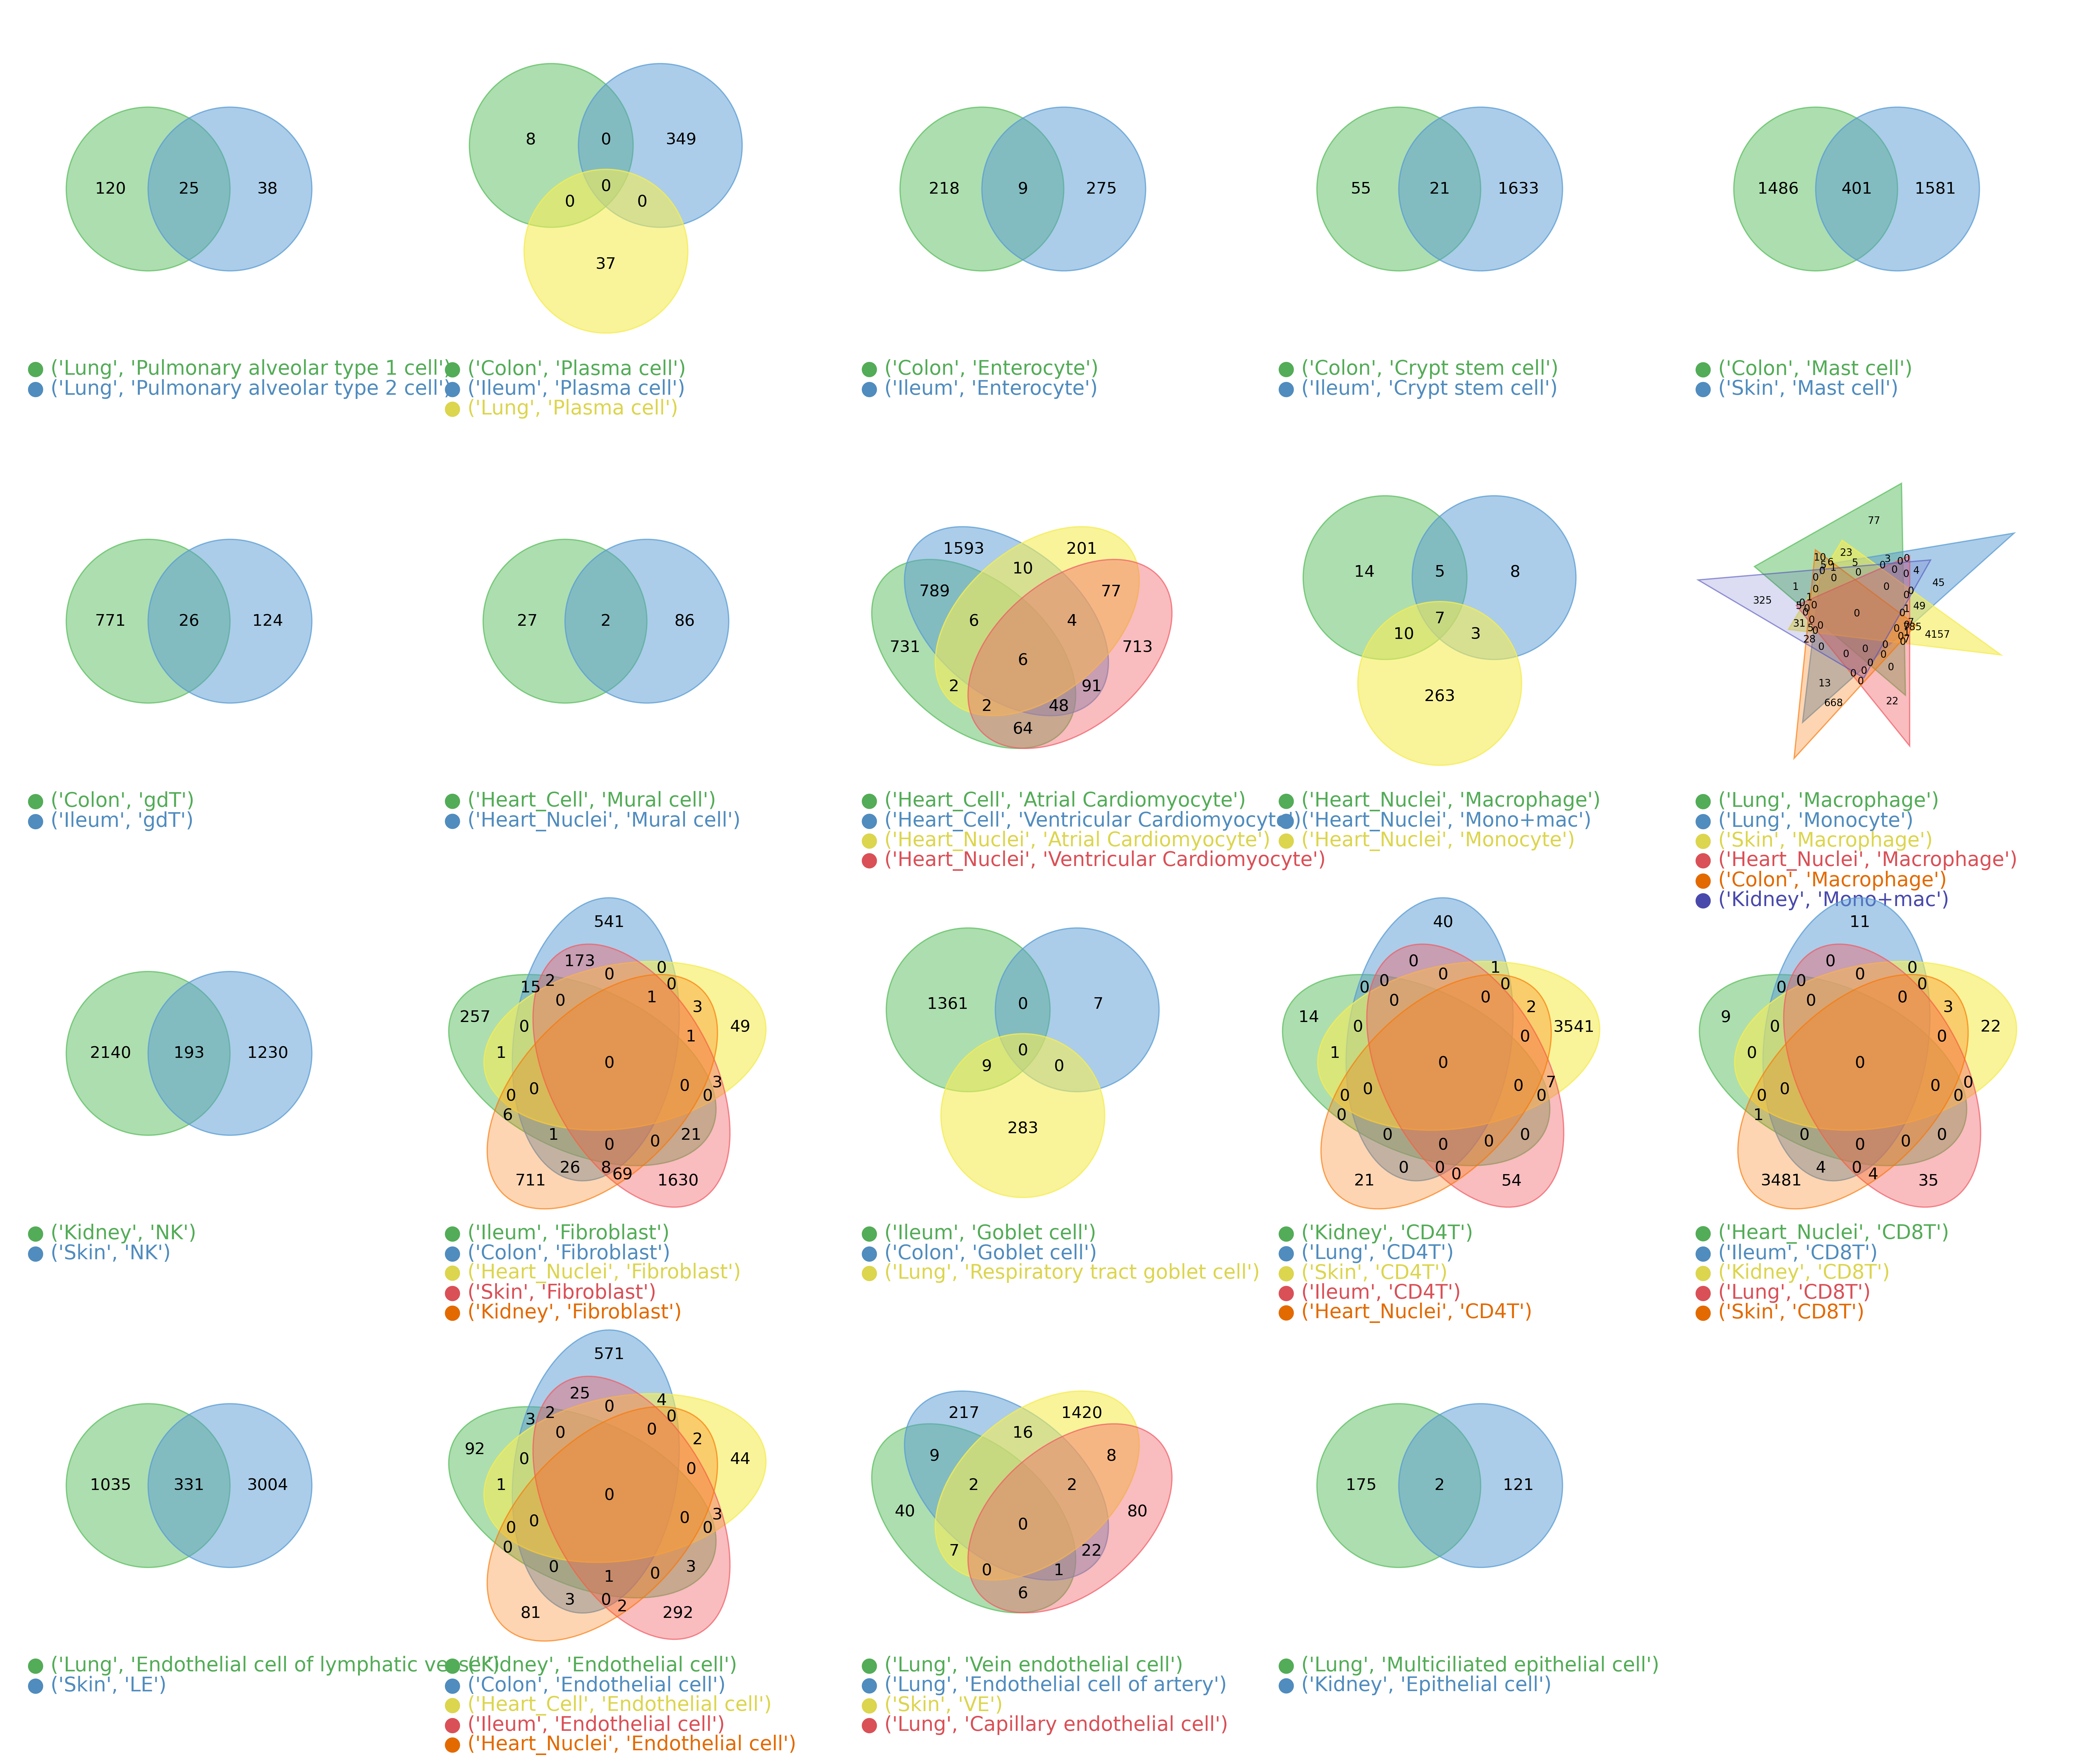

In [22]:
build_venn_for_sublists(sp_sigs, ct_sigs_list, n_cols=5)

In [23]:
t_sigs_list = [
    [
        ("Colon", "Crypt stem cell"),
        ("Colon", "Endothelial cell"),
        ("Colon", "Enterocyte"),
        ("Colon", "Fibroblast"),
        ("Colon", "Goblet cell"),
        ("Colon", "Macrophage"),
    ],
    [
        ("Colon", "Mast cell"),
        ("Colon", "Plasma cell"),
        ("Colon", "Transit amplifying cell"),
        ("Colon", "Tuft cell"),
        ("Colon", "gdT"),
    ],
    [
        ("Heart_Cell", "Atrial Cardiomyocyte"),
        ("Heart_Cell", "Endothelial cell"),
        ("Heart_Cell", "Mural cell"),
        ("Heart_Cell", "Ventricular Cardiomyocyte"),
    ],
    [
        ("Heart_Nuclei", "Adipocyte"),
        ("Heart_Nuclei", "Atrial Cardiomyocyte"),
        ("Heart_Nuclei", "CD4T"),
        ("Heart_Nuclei", "CD8T"),
        ("Heart_Nuclei", "Endothelial cell"),
        ("Heart_Nuclei", "Fibroblast"),
    ],
    [
        ("Heart_Nuclei", "Macrophage"),
        ("Heart_Nuclei", "Mono+mac"),
        ("Heart_Nuclei", "Monocyte"),
        ("Heart_Nuclei", "Mural cell"),
        ("Heart_Nuclei", "Neural cell"),
        ("Heart_Nuclei", "Ventricular Cardiomyocyte"),
    ],
    [
        ("Ileum", "B cell"),
        ("Ileum", "CD4T"),
        ("Ileum", "CD8T"),
        ("Ileum", "Crypt stem cell"),
        ("Ileum", "Endothelial cell"),
        ("Ileum", "Enterocyte"),
    ],
    [
        ("Ileum", "Enteroendocrine cell"),
        ("Ileum", "Fibroblast"),
        ("Ileum", "Goblet cell"),
        ("Ileum", "Paneth cell"),
        ("Ileum", "Plasma cell"),
        ("Ileum", "gdT"),
    ],
    [
        ("Kidney", "CD4T"),
        ("Kidney", "CD8T"),
        ("Kidney", "Mono+mac"),
        ("Kidney", "NK"),
    ],
    [
        ("Kidney", "Endothelial cell"),
        ("Kidney", "Epithelial cell"),
        ("Kidney", "Fibroblast"),
    ],
    [
        ("Lung", "Adventitial cell"),
        ("Lung", "Alveolar adventitial fibroblast"),
        ("Lung", "Basal cell"),
        ("Lung", "Basophil"),
        ("Lung", "CD4T"),
        ("Lung", "CD8T"),
    ],
    [
        ("Lung", "Capillary endothelial cell"),
        ("Lung", "Endothelial cell of artery"),
        ("Lung", "Endothelial cell of lymphatic vessel"),
        ("Lung", "Vein endothelial cell"),
        ("Lung", "Macrophage"),
        ("Lung", "Monocyte"),
    ],
    [
        ("Lung", "Club cell"),
        ("Lung", "Multiciliated epithelial cell"),
        ("Lung", "Plasma cell"),
        ("Lung", "Pulmonary alveolar type 1 cell"),
        ("Lung", "Pulmonary alveolar type 2 cell"),
        ("Lung", "Respiratory tract goblet cell"),
    ],
    [
        ("Skin", "CD4T"),
        ("Skin", "CD8T"),
        ("Skin", "Treg"),
        ("Skin", "NK"),
    ],
    [
        ("Skin", "Differentiated_KC"),
        ("Skin", "Melanocyte"),
        ("Skin", "Fibroblast"),
        ("Skin", "LE"),
        ("Skin", "VE"),
    ],
    [
        ("Skin", "Pericyte"),
        ("Skin", "DC"),
        ("Skin", "Macrophage"),
        ("Skin", "Mast cell"),
    ],
]

In [24]:
len(t_sigs_list)

15

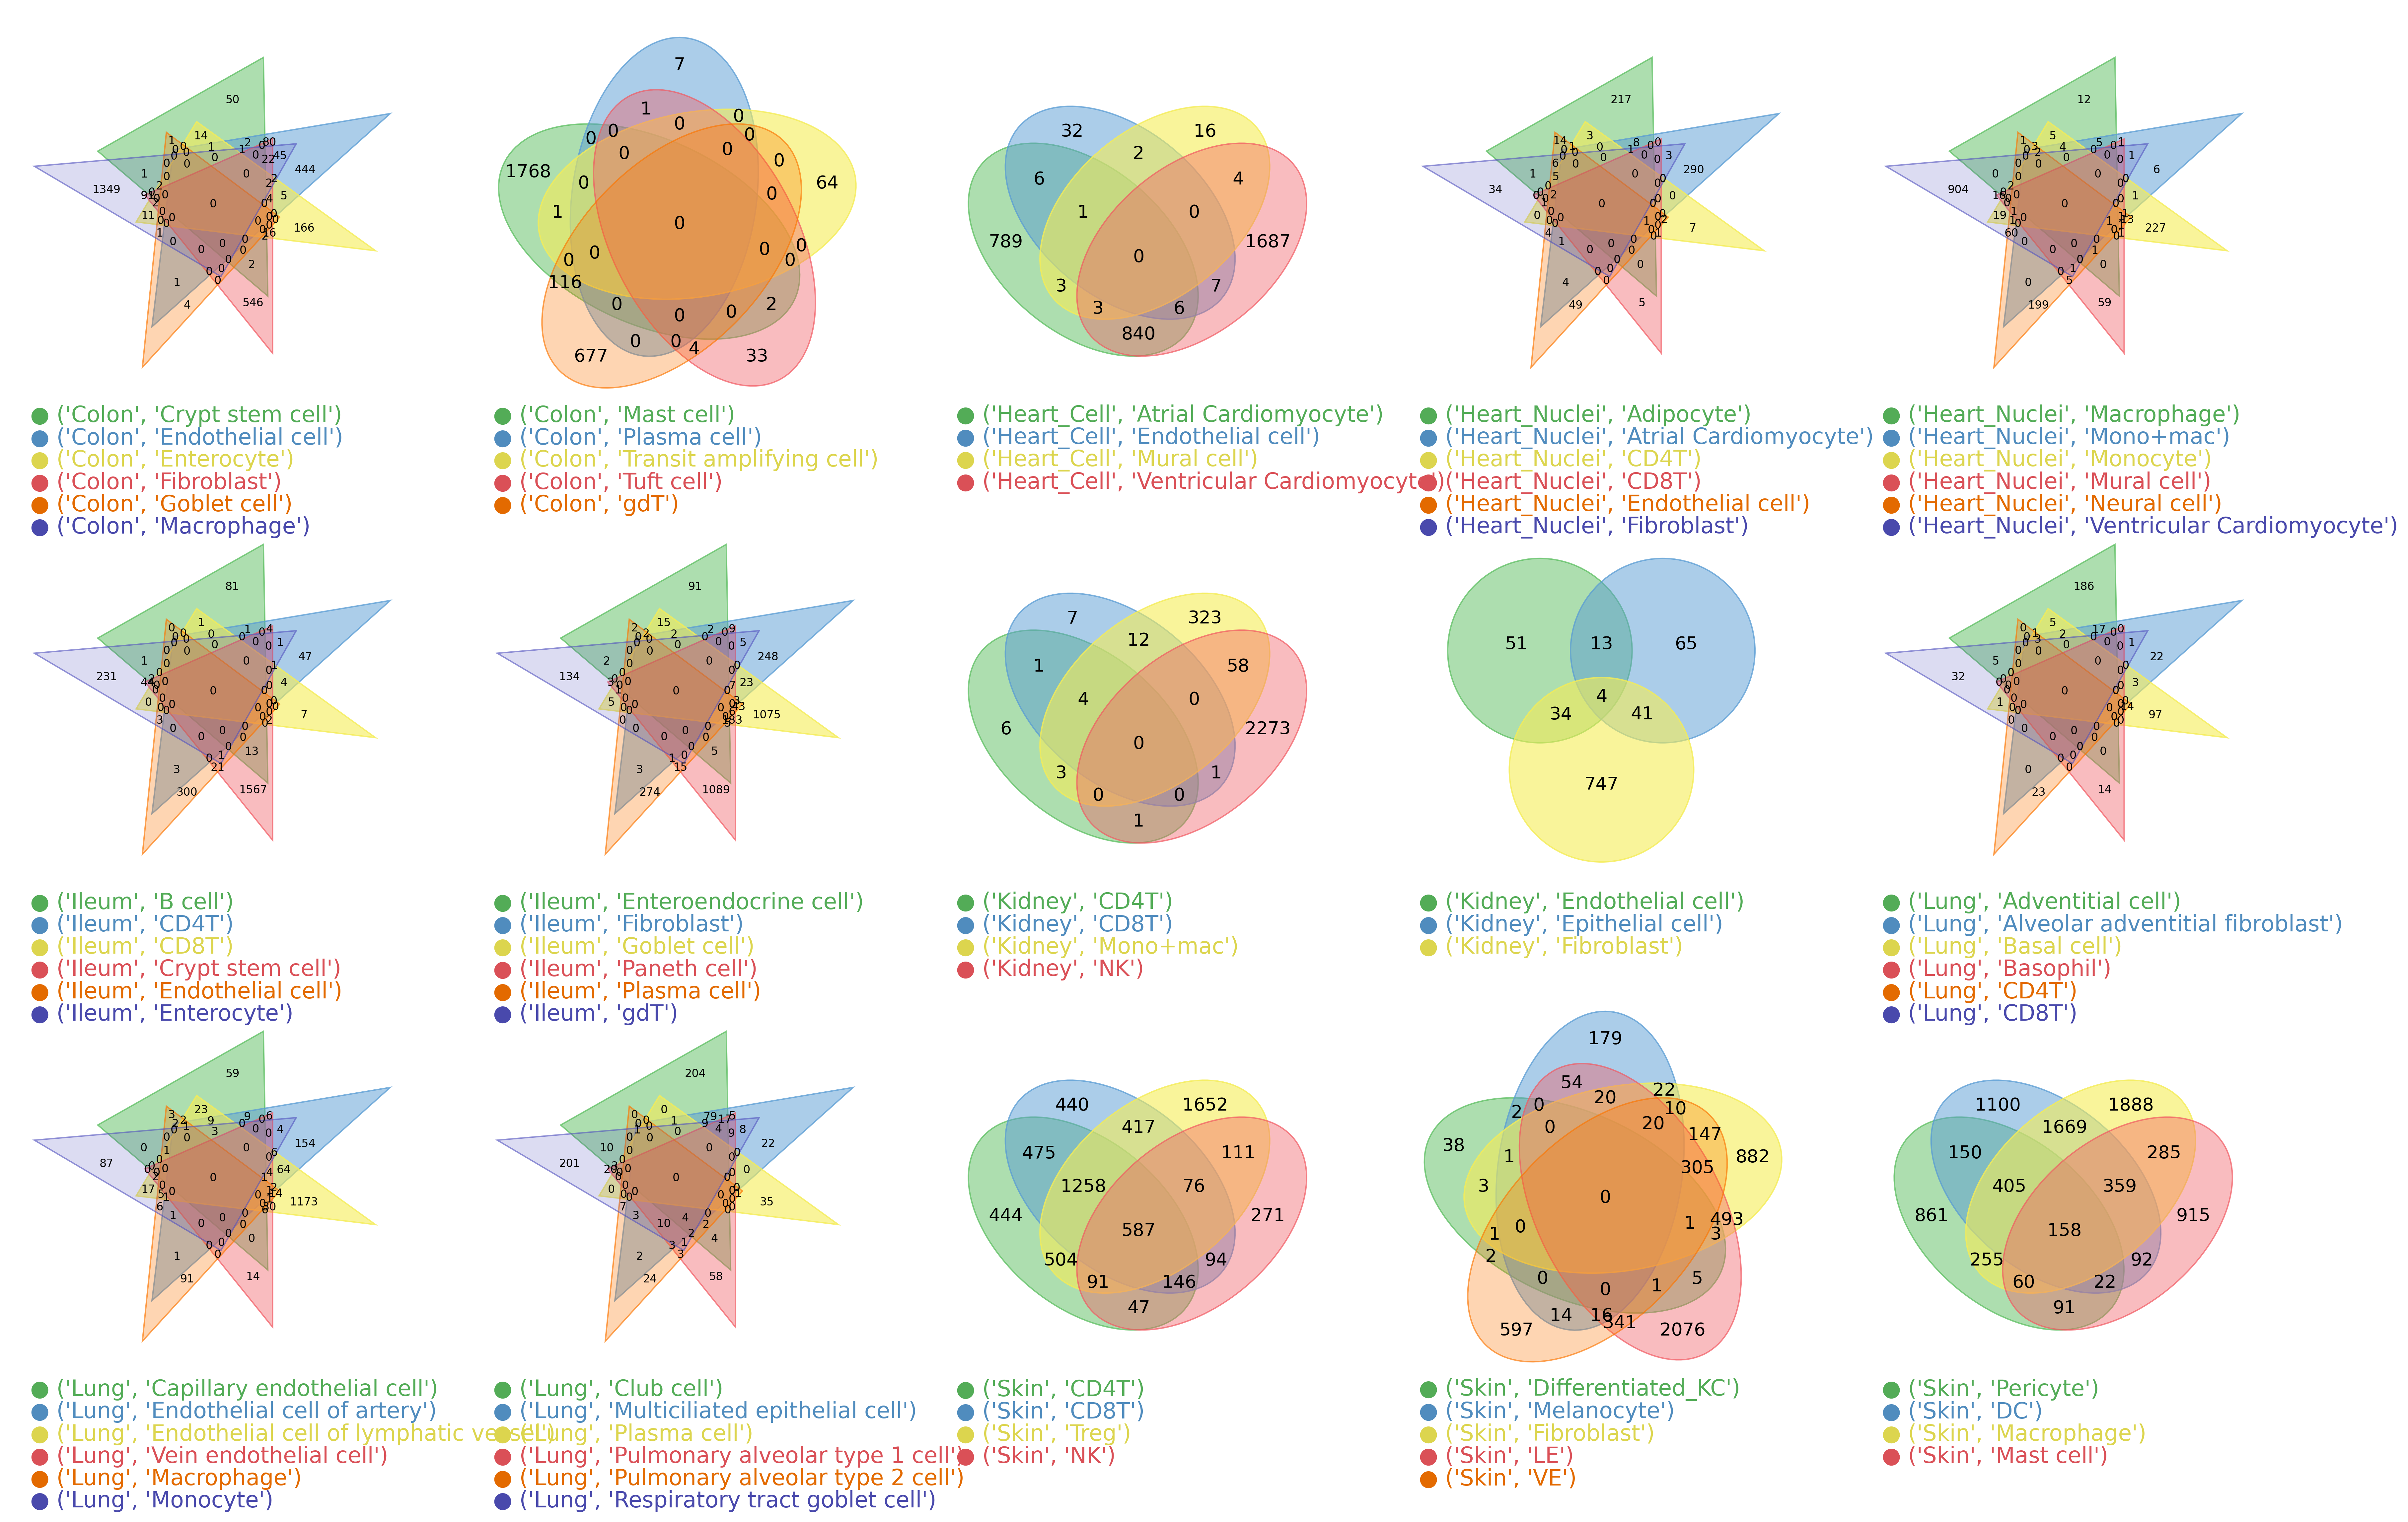

In [25]:
build_venn_for_sublists(sp_sigs, t_sigs_list, n_cols=5)

### 3. Universal sen signatures genes intersection

Переменные определены выше (1)

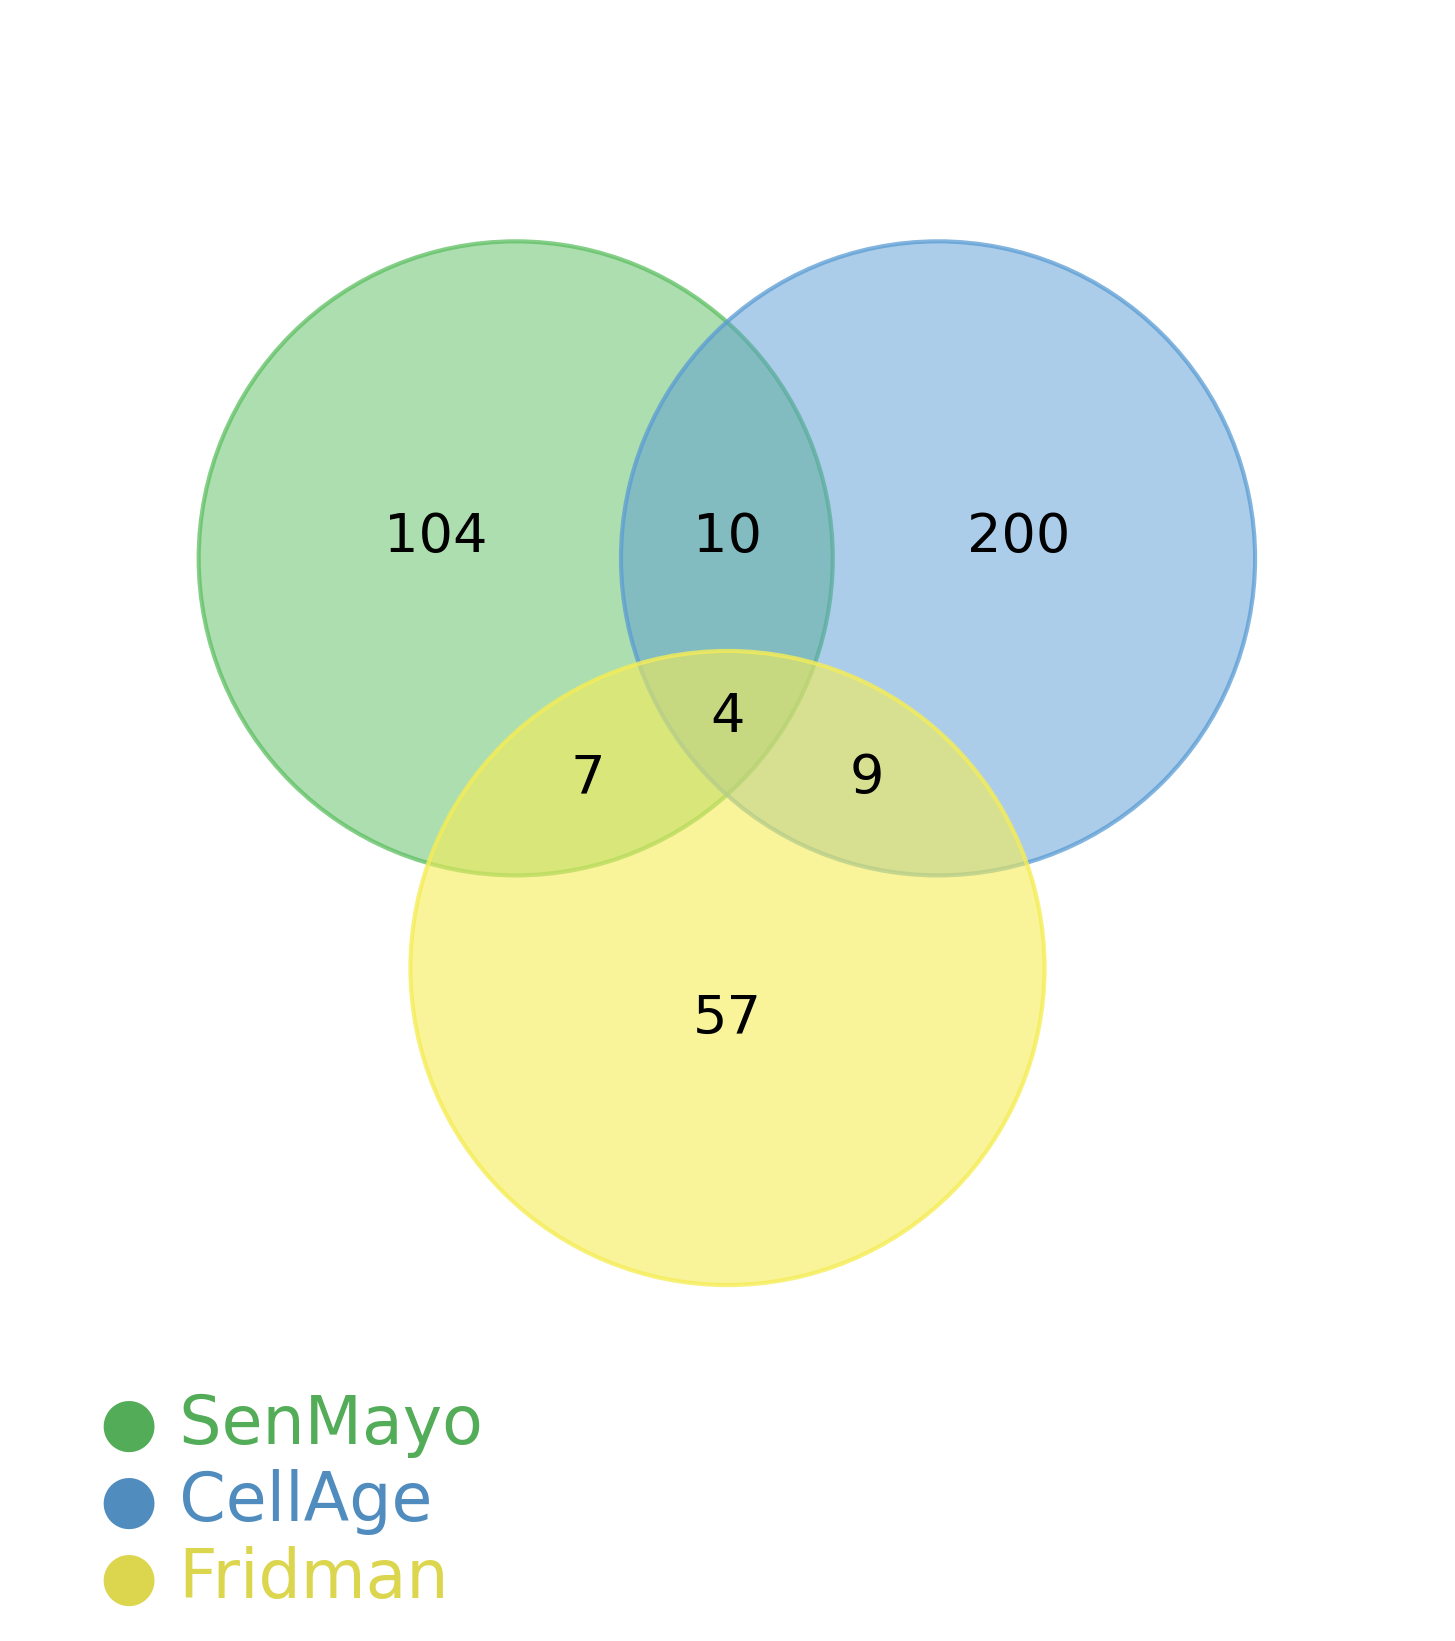

In [29]:
# 1. Формируем списки множеств и их названий для 3 ваших переменных
gene_sets = [set(senmayo_genes), set(cellage_genes), set(fridm_genes)]

names = ["SenMayo", "CellAge", "Fridman"]

# 2. Создаем одну фигуру (1 строка, 1 столбец) с высоким качеством (dpi=300)
# Пропорции 6x7 дают чуть больше места снизу для аккуратного размещения легенды
fig, ax = plt.subplots(figsize=(6, 7), dpi=300)

# 3. Вызываем вашу готовую функцию plot_venn
# Она сама определит, что переданных множеств 3, вызовет venn3,
# перенесет круги, расставит крупные черные цифры и построит список под графиком
plot_venn(gene_sets=gene_sets, names=names, ax=ax, title=None)

# 4. Отображаем результат
plt.show()

#### 3.2 down

/opt/conda/envs/scenv/lib/python3.11/site-packages/venn/_backwards_compatibility.py:15: UserWarning: `get_labels()` is retained for backwards compatibility; use `generate_petal_labels()` or the higher level `venn()` instead
  warn((
/opt/conda/envs/scenv/lib/python3.11/site-packages/venn/_backwards_compatibility.py:30: UserWarning: `venn2()` is retained for backwards compatibility; use `venn()` instead
  warn((


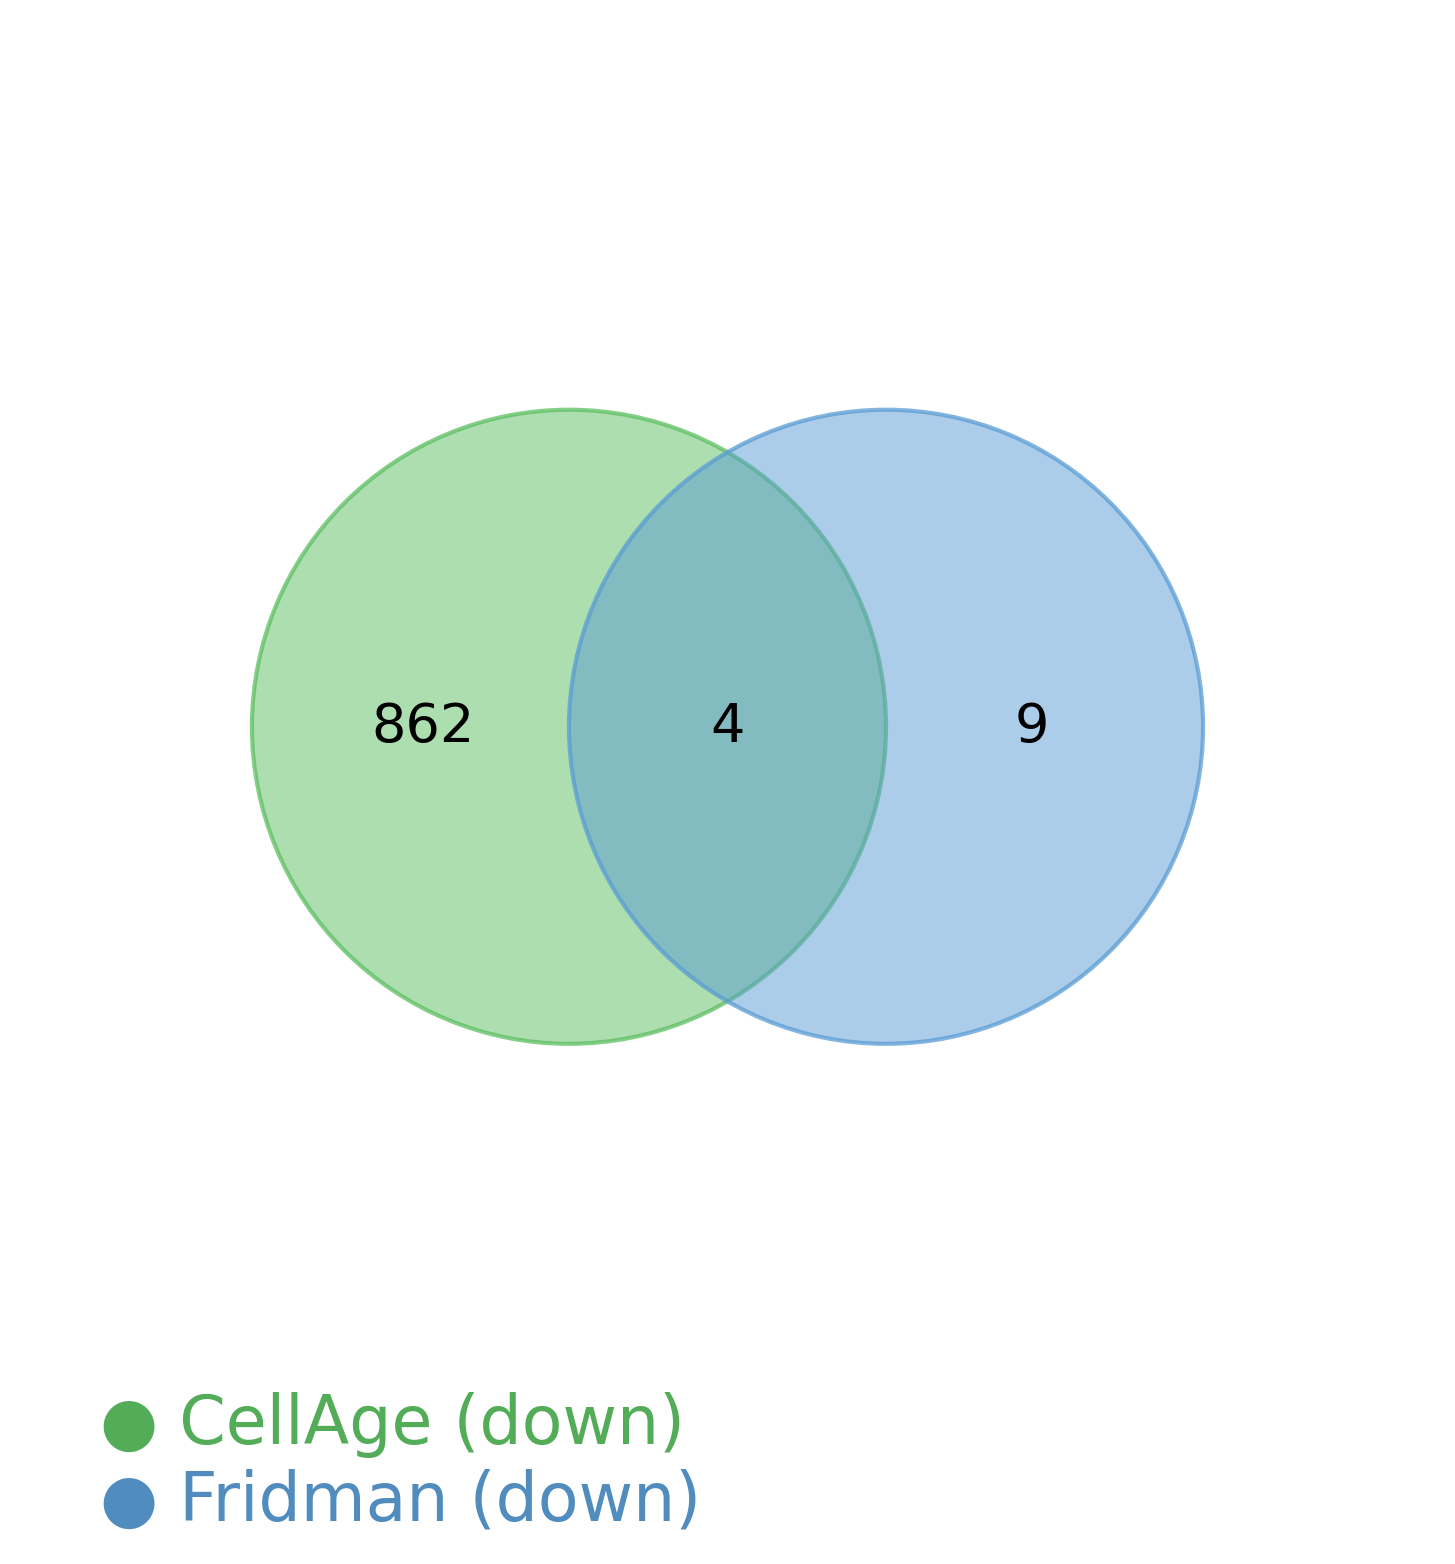

In [63]:
gene_sets = [set(cellage_dn), set(fridm_dn)]

names = ["CellAge (down)", "Fridman (down)"]

# 2. Создаем одну фигуру (1 строка, 1 столбец) с высоким качеством (dpi=300)
# Пропорции 6x7 дают чуть больше места снизу для аккуратного размещения легенды
fig, ax = plt.subplots(figsize=(6, 7), dpi=300)

# 3. Вызываем вашу готовую функцию plot_venn
# Она сама определит, что переданных множеств 3, вызовет venn3,
# перенесет круги, расставит крупные черные цифры и построит список под графиком
plot_venn(gene_sets=gene_sets, names=names, ax=ax, title=None)

# 4. Отображаем результат
plt.show()

### 4. SenCID identities genes intersection

In [30]:
sid_genes = {
    "SID1": [
        "CCND1",
        "CDKN1A",
        "PCNA",
        "CDK6",
        "ZMAT3",
        "EGR1",
        "BHLHE40",
        "MYLK",
        "EDN1",
        "F3",
        "PCK2",
        "BTG2",
        "TRIM22",
        "OSTM1",
        "DEPDC1",
        "NCEH1",
        "TP53INP1",
        "PRICKLE2",
        "PGM2L1",
    ],
    "SID2": [
        "CCND1",
        "HMGB2",
        "CKB",
        "CDKN2C",
        "EDN1",
        "FANCE",
        "PLAT",
        "ENC1",
        "SV2A",
        "PHGDH",
        "ANGPTL4",
        "MFSD1",
        "CDCA3",
    ],
    "SID3": [
        "CDK1",
        "LMNB1",
        "SOD2",
        "CCND1",
        "FGF2",
        "GDF15",
        "IGFBP3",
        "IGFBP5",
        "MKI67",
        "SERPINE1",
        "TOP2A",
        "CCNE1",
        "CBX4",
        "PRKCD",
        "CDKN2D",
        "CDK6",
        "SLC16A7",
        "RNASET2",
        "BUB1B",
        "TAGLN",
        "S100A6",
        "RXRB",
        "RRM2",
        "RING1",
        "CDKN2AIP",
        "PLAUR",
        "MYBL2",
        "MAP3K5",
        "SMAD1",
        "JAK2",
        "HNRNPA1",
        "HELLS",
        "NPTXR",
        "ETS2",
        "EGR1",
        "DUSP6",
        "DUSP4",
        "E2F7",
        "CKB",
        "UBE2C",
        "EHMT2",
        "NDRG1",
        "CD55",
        "ICAM3",
        "ITGA2",
        "BHLHE40",
        "HDAC4",
        "ING2",
        "MYLK",
        "PRKCH",
        "RUNX1",
        "SGK1",
        "TGFB1I1",
        "AMPD3",
        "SLC25A4",
        "AOX1",
        "BARD1",
        "CALD1",
        "CTSC",
        "CKS2",
        "COL6A3",
        "COL15A1",
        "SLC31A2",
        "DNASE1L1",
        "DPYSL3",
        "EDN1",
        "EMP2",
        "EPAS1",
        "F3",
        "FAT1",
        "FKBP5",
        "FLNC",
        "FN1",
        "STMN1",
        "LOX",
        "LOXL2",
        "LRP1",
        "MATN2",
        "MDK",
        "MEST",
        "MXI1",
        "PCOLCE",
        "SERPINF1",
        "PFKP",
        "PLAT",
        "PRPS1",
        "PTPRK",
        "PTX3",
        "SAT1",
        "SLC1A1",
        "SOX4",
        "SVIL",
        "SYT1",
        "TIMP3",
        "TMPO",
        "ZNF22",
        "BTG2",
        "CDC7",
        "STC2",
        "TNFRSF10D",
        "P4HA2",
        "SYNGR2",
        "SYNGR1",
        "DHRS3",
        "SLIT2",
        "ARHGAP29",
        "KIF23",
        "ATP6V1G1",
        "SH3PXD2A",
        "DLGAP5",
        "HEPH",
        "KIF14",
        "TROAP",
        "EDIL3",
        "KIF20A",
        "CITED2",
        "NDC80",
        "PGRMC2",
        "PLK4",
        "RAB40B",
        "CNTRL",
        "DNAJB4",
        "CIT",
        "DUSP10",
        "OIP5",
        "COBLL1",
        "NCAPH",
        "PLA2G15",
        "KIF4A",
        "LMOD1",
        "MPC2",
        "CYFIP2",
        "TSPAN13",
        "TNFRSF21",
        "EML4",
        "SLC43A3",
        "ARHGEF3",
        "ANGPTL4",
        "SCARA3",
        "DTL",
        "RAB6B",
        "CYB5R1",
        "GNG2",
        "ANLN",
        "MANSC1",
        "CEP55",
        "MCM10",
        "PLXNA3",
        "CDK5RAP2",
        "SULF2",
        "EMC7",
        "OLFML3",
        "PLSCR4",
        "KIAA1191",
        "NIPAL3",
        "SPC25",
        "RHOU",
        "FAM111A",
        "CLSPN",
        "PERP",
        "OGFRL1",
        "SCD5",
        "ARMC9",
        "FAM214B",
        "COLEC12",
        "BRIP1",
        "SGIP1",
        "MED30",
        "SLFN11",
        "ZNF300",
        "FANK1",
        "TIFA",
        "AHNAK2",
        "PIK3IP1",
        "FBXO32",
        "CCDC58",
        "FAM43A",
        "GPR155",
        "ZNF610",
        "ZNF367",
        "OTUD1",
        "ASPM",
        "GAS2L3",
        "NCKAP5",
        "FAM111B",
        "ARHGEF37",
    ],
    "SID4": [
        "CDKN2A",
        "CDKN2B",
        "GDF15",
        "SERPINE1",
        "CCNE1",
        "TBX2",
        "CEBPB",
        "ARHGAP18",
        "RING1",
        "MAPK10",
        "PLAUR",
        "IGF1R",
        "HSPB1",
        "CABIN1",
        "ETS2",
        "ETS1",
        "CLU",
        "BMP2",
        "GEM",
        "INHBA",
        "MMP14",
        "ARPC1B",
        "BAG3",
        "BHLHE40",
        "DHCR24",
        "SENP7",
        "SGK1",
        "ARF4",
        "STS",
        "CD81",
        "CTSC",
        "COL6A3",
        "COL8A1",
        "DPYSL3",
        "EMP2",
        "EPAS1",
        "F3",
        "FN1",
        "IFI6",
        "HAS2",
        "ITGAV",
        "ITGB5",
        "LAMC1",
        "MEST",
        "SERPINF1",
        "PPP1R3C",
        "SAT1",
        "TAP1",
        "TGM2",
        "SLC7A5",
        "ADAM19",
        "TNFRSF10D",
        "SPHK1",
        "SLC5A6",
        "SYNGR2",
        "DHRS3",
        "SNPH",
        "CPQ",
        "BLCAP",
        "PRSS23",
        "CIT",
        "IRAK3",
        "FILIP1L",
        "COBLL1",
        "TBC1D9",
        "OSTM1",
        "GNG2",
        "SAMD9",
        "ERCC6L",
        "CENPJ",
        "FIGNL1",
        "PERP",
        "TMBIM1",
        "PIP4K2C",
        "BORA",
        "PGBD1",
        "ARRDC4",
        "ZNF300",
        "HTRA3",
        "CYP2U1",
        "FBXO32",
        "FRMD6",
        "SLC43A2",
        "FAM43A",
        "LACC1",
        "CCDC138",
        "DCBLD1",
    ],
    "SID5": [
        "LMNB1",
        "CCL2",
        "GDF15",
        "IGFBP3",
        "MKI67",
        "SERPINE1",
        "TWIST1",
        "CCNE1",
        "PLAUR",
        "PIM1",
        "IRS1",
        "G6PD",
        "EEF1A1",
        "DUSP6",
        "DUSP4",
        "INHBA",
        "ITGA2",
        "ITPKB",
        "SIX1",
        "STK32C",
        "ABCA3",
        "ASAH1",
        "BPGM",
        "CDC25B",
        "COL15A1",
        "DPYSL3",
        "F3",
        "FUCA1",
        "IFI6",
        "GLS",
        "HAGH",
        "HAS2",
        "INSIG1",
        "STMN1",
        "MANBA",
        "MDK",
        "PCOLCE",
        "SERPINF1",
        "SERPINI1",
        "PLAT",
        "PLOD2",
        "PPP1R3C",
        "PTMA",
        "SCD",
        "SFRP1",
        "SLC1A1",
        "TAP1",
        "KHSRP",
        "CREG1",
        "GGH",
        "SYNGR2",
        "SLIT2",
        "AKAP12",
        "ISG15",
        "ATP6AP2",
        "MLLT11",
        "CBX5",
        "ORC6",
        "TUBG2",
        "OSTM1",
        "RAB6B",
        "DHRS7",
        "TM7SF3",
        "GNG2",
        "USP53",
        "HERC6",
        "SULF2",
        "EMC7",
        "OLFML3",
        "NCEH1",
        "NABP1",
        "COLEC12",
        "SLC9A7",
        "LMBRD2",
        "FANK1",
        "ATG4A",
        "WDR63",
        "FAM43A",
        "DOCK11",
        "PRICKLE2",
        "PGM2L1",
        "SLC46A3",
        "IGIP",
    ],
    "SID6": [
        "MYC",
        "AURKB",
        "CCND1",
        "CDKN1A",
        "CDKN2B",
        "ID1",
        "IGFBP3",
        "IGFBP5",
        "LMNA",
        "MKI67",
        "MMP2",
        "STAT1",
        "TWIST1",
        "PCNA",
        "CCNE1",
        "TBX2",
        "PRKCD",
        "ARHGAP18",
        "WNT5A",
        "UBA52",
        "TAGLN",
        "SLC13A3",
        "RRM2",
        "RRM1",
        "RPS27A",
        "RPL5",
        "PSMB5",
        "MAPK10",
        "ERRFI1",
        "PGD",
        "MYBL2",
        "SMAD6",
        "SMAD3",
        "SMAD1",
        "JUN",
        "CDC26",
        "ETS2",
        "ENG",
        "EEF1B2",
        "DUSP4",
        "E2F7",
        "JDP2",
        "CLU",
        "CKB",
        "UBE2C",
        "CENPA",
        "ANAPC10",
        "CD9",
        "CSF1",
        "CXCL12",
        "FAS",
        "IGFBP6",
        "VEGFA",
        "BHLHE40",
        "CDK2AP1",
        "DDB2",
        "DHCR24",
        "LGALS3",
        "NUAK1",
        "PMVK",
        "SIX1",
        "YAP1",
        "ZFP36",
        "ABCA3",
        "ANGPT1",
        "SLC25A5",
        "ANXA4",
        "CDC20",
        "CENPE",
        "CENPF",
        "CKS2",
        "COL6A3",
        "COL8A1",
        "DAB2",
        "DGKA",
        "GADD45A",
        "DNASE1L1",
        "DPYSL3",
        "EMP2",
        "EPAS1",
        "EPHA4",
        "CLN8",
        "ERH",
        "FBL",
        "ETV4",
        "FANCA",
        "FHL1",
        "IFI6",
        "GAS6",
        "HAS2",
        "HLA-B",
        "HMGB3",
        "HMMR",
        "HNRNPH1",
        "SP110",
        "IFIT1",
        "KIF11",
        "LAMC1",
        "STMN1",
        "LIPA",
        "LOXL2",
        "LSAMP",
        "MDK",
        "MEST",
        "ODC1",
        "PAM",
        "ENPP2",
        "PLCB4",
        "PRIM1",
        "PRRG1",
        "HTRA1",
        "RPL4",
        "RPS9",
        "RPS16",
        "SORT1",
        "SHMT2",
        "SLC1A1",
        "SOX4",
        "THBS1",
        "TPM2",
        "TTK",
        "BTG2",
        "SLC7A5",
        "ENC1",
        "PEA15",
        "ADAM19",
        "GGH",
        "SPHK1",
        "P4HA2",
        "PAPSS2",
        "SYNGR2",
        "SYNGR1",
        "TRIP13",
        "AKAP12",
        "ISG15",
        "HDAC9",
        "MELK",
        "GINS1",
        "GFPT2",
        "AASS",
        "TRIM22",
        "NDC80",
        "IFITM3",
        "SEMA3C",
        "RAD51AP1",
        "FILIP1L",
        "OIP5",
        "COBLL1",
        "MAPRE3",
        "KIAA0930",
        "NCAPH",
        "DDAH1",
        "DDX58",
        "APOL2",
        "RAD54B",
        "POC1A",
        "CNRIP1",
        "CLIP3",
        "TMEM251",
        "SLC17A5",
        "CYFIP2",
        "DKK3",
        "TNFRSF21",
        "UBE2T",
        "LRP12",
        "RRM2B",
        "ANGPTL4",
        "NUSAP1",
        "SCARA3",
        "DPH5",
        "COQ3",
        "MIS18A",
        "GNG2",
        "RIN2",
        "SAMD9",
        "HAUS4",
        "HERC6",
        "ZWILCH",
        "CDCA8",
        "CEP55",
        "MNS1",
        "MCM10",
        "CDCA7L",
        "PLXNA3",
        "HHAT",
        "NXT2",
        "SULF2",
        "OLFML3",
        "PRTFDC1",
        "RCN3",
        "C3orf14",
        "NCEH1",
        "LSM2",
        "CLSPN",
        "CENPK",
        "NABP1",
        "NT5DC2",
        "CENPH",
        "NUP85",
        "KIF18A",
        "NUF2",
        "ANTXR1",
        "SLC9A7",
        "NEXN",
        "ZNF300",
        "HTRA3",
        "FBXO32",
        "RMI2",
        "WDR63",
        "LACC1",
        "CKAP2L",
        "ARL6IP6",
        "CDCA2",
        "ITPRIPL2",
        "ZNF610",
        "PRICKLE2",
        "SAMD9L",
        "HYLS1",
        "ASPM",
        "GAS2L3",
        "FAM111B",
        "CENPW",
        "ARHGEF37",
        "SHC4",
    ],
}

/opt/conda/envs/scenv/lib/python3.11/site-packages/venn/_backwards_compatibility.py:15: UserWarning: `get_labels()` is retained for backwards compatibility; use `generate_petal_labels()` or the higher level `venn()` instead
  warn((
/opt/conda/envs/scenv/lib/python3.11/site-packages/venn/_backwards_compatibility.py:30: UserWarning: `venn6()` is retained for backwards compatibility; use `venn()` instead
  warn((


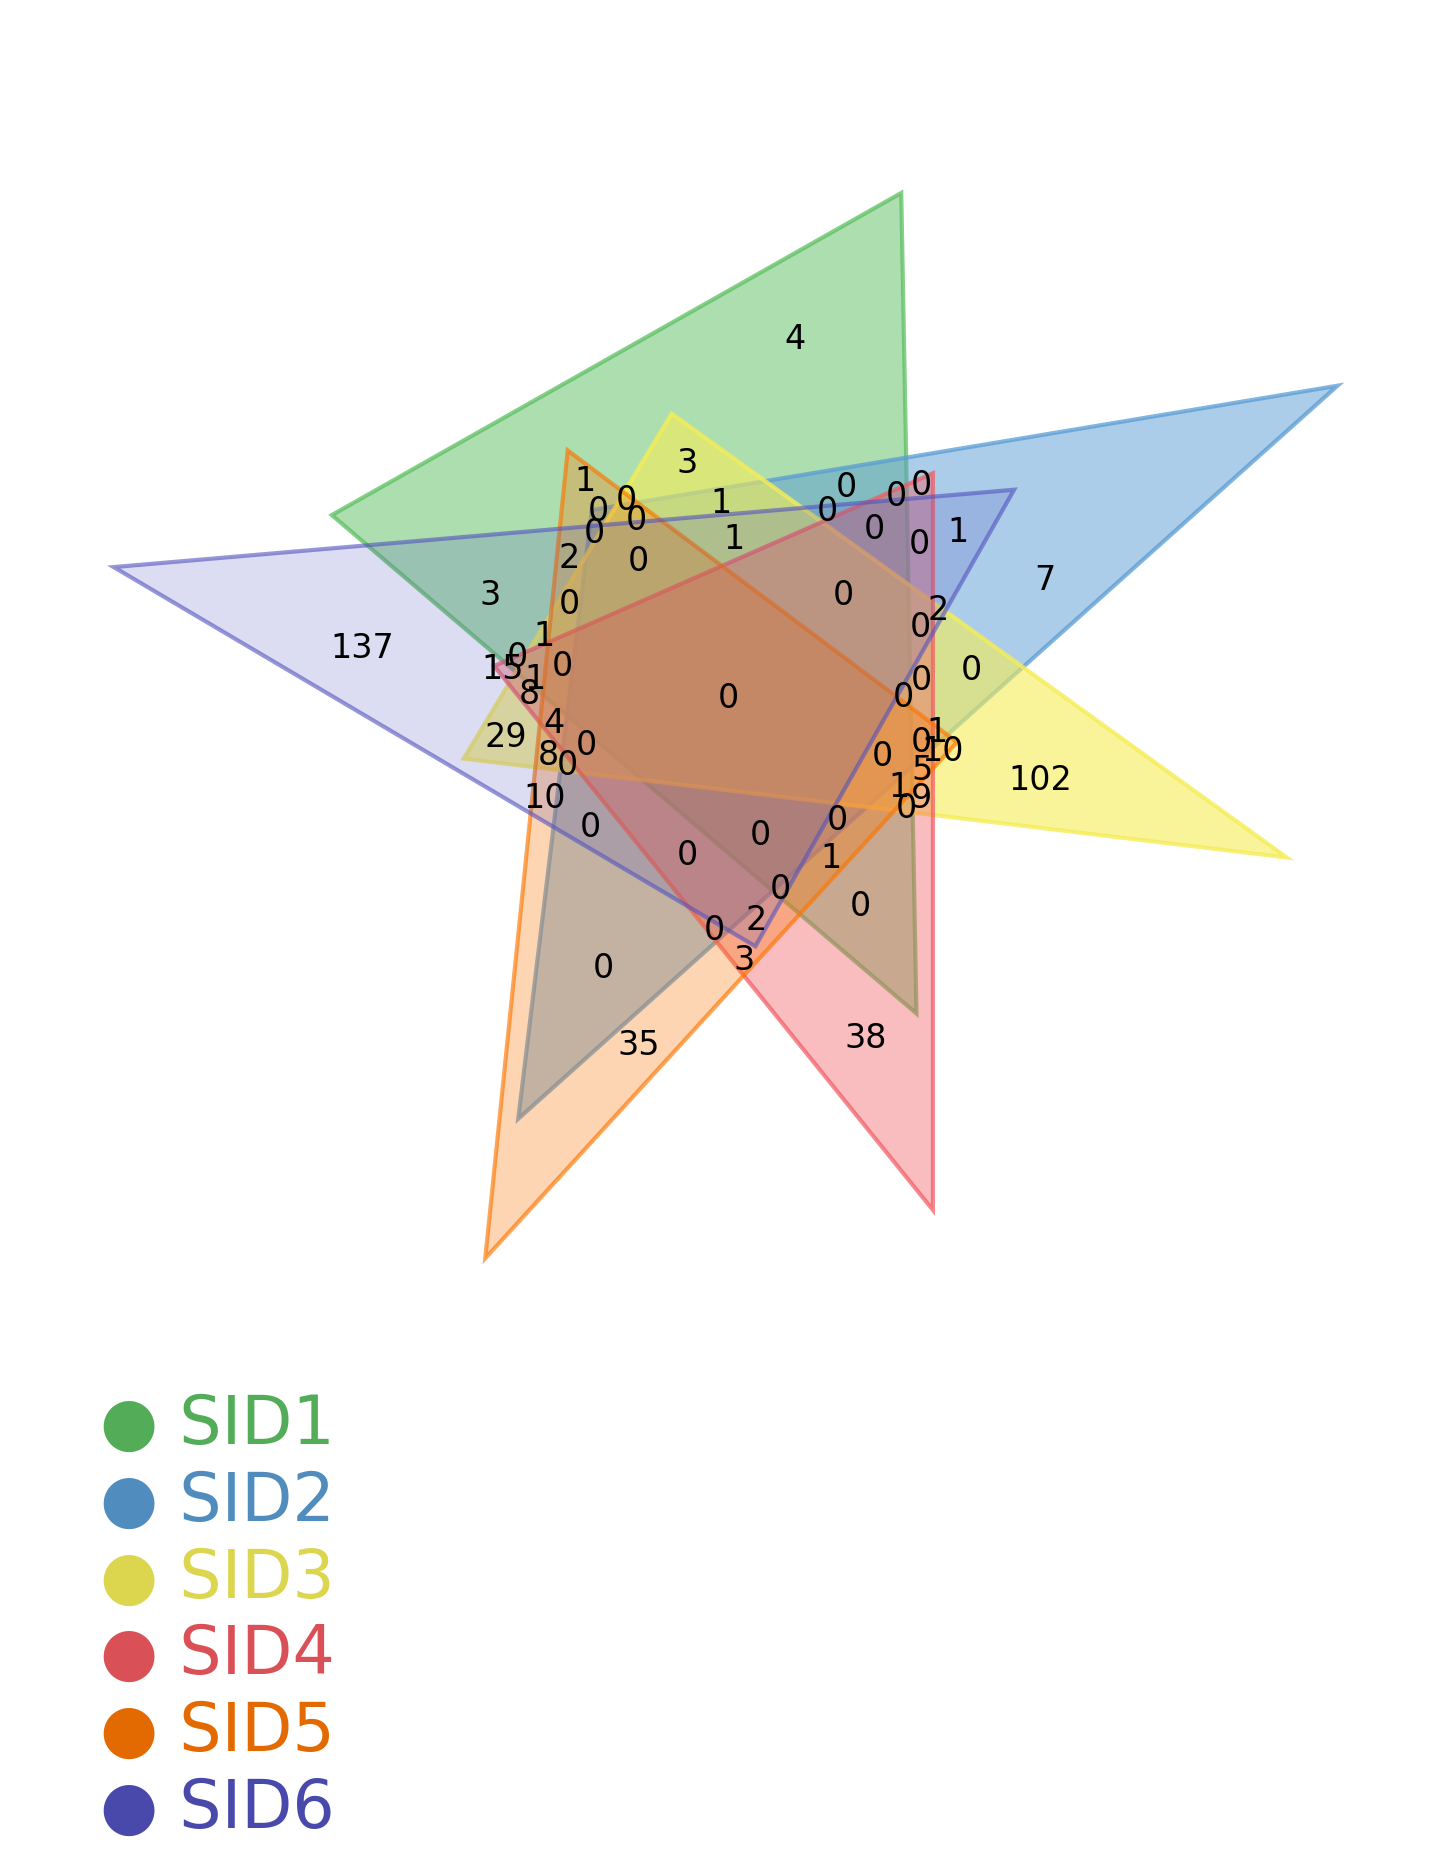

In [32]:
# 1. Формируем списки множеств и их названий для 3 ваших переменных
gene_sets = [set(g) for g in sid_genes.values()]

names = [n for n in sid_genes.keys()]

# 2. Создаем одну фигуру (1 строка, 1 столбец) с высоким качеством (dpi=300)
# Пропорции 6x7 дают чуть больше места снизу для аккуратного размещения легенды
fig, ax = plt.subplots(figsize=(6, 7), dpi=300)

# 3. Вызываем вашу готовую функцию plot_venn
# Она сама определит, что переданных множеств 3, вызовет venn3,
# перенесет круги, расставит крупные черные цифры и построит список под графиком
plot_venn(gene_sets=gene_sets, names=names, ax=ax, title=None)

# 4. Отображаем результат
plt.show()

### 5. All senepy & all sid genes intersection

In [41]:
all_sp = []
for sig_genes in sp_sigs.values():
    for g, _ in sig_genes:
        all_sp.append(g)
all_sp_set = set(all_sp)

all_sid = []
for sig_genes in sid_genes.values():
    all_sid.extend(sig_genes)
all_sid_set = set(all_sid)

In [ ]:
coregs_df = pd.read_csv(".././7_5_coreGS_v2_deepscence.csv")
coregs_df.head()

,Unnamed: 0,occurrence,direction,gene_symbol_human,gene_symbol_mouse
0,IL6,7,up,IL6,Il6
1,IGFBP3,7,up,IGFBP3,Igfbp3
2,EGFR,7,down,EGFR,Egfr
3,SERPINE1,6,up,SERPINE1,Serpine1
4,IGFBP1,6,up,IGFBP1,Igfbp1


In [49]:
coregs_df["occurrence"] = coregs_df["occurrence"].astype(int)
coregs_df = coregs_df[coregs_df.occurrence >= 5]
coregs_df.shape

(39, 5)

In [64]:
coregs_genes = coregs_df[coregs_df.direction == "up"]["gene_symbol_human"].to_list()
all_ds_set = set(coregs_genes)

In [65]:
len(all_ds_set)

23

In [37]:
coregs_df.shape

(2966, 5)

In [36]:
len(coregs_genes)

1239

/opt/conda/envs/scenv/lib/python3.11/site-packages/venn/_backwards_compatibility.py:30: UserWarning: `venn3()` is retained for backwards compatibility; use `venn()` instead
  warn((


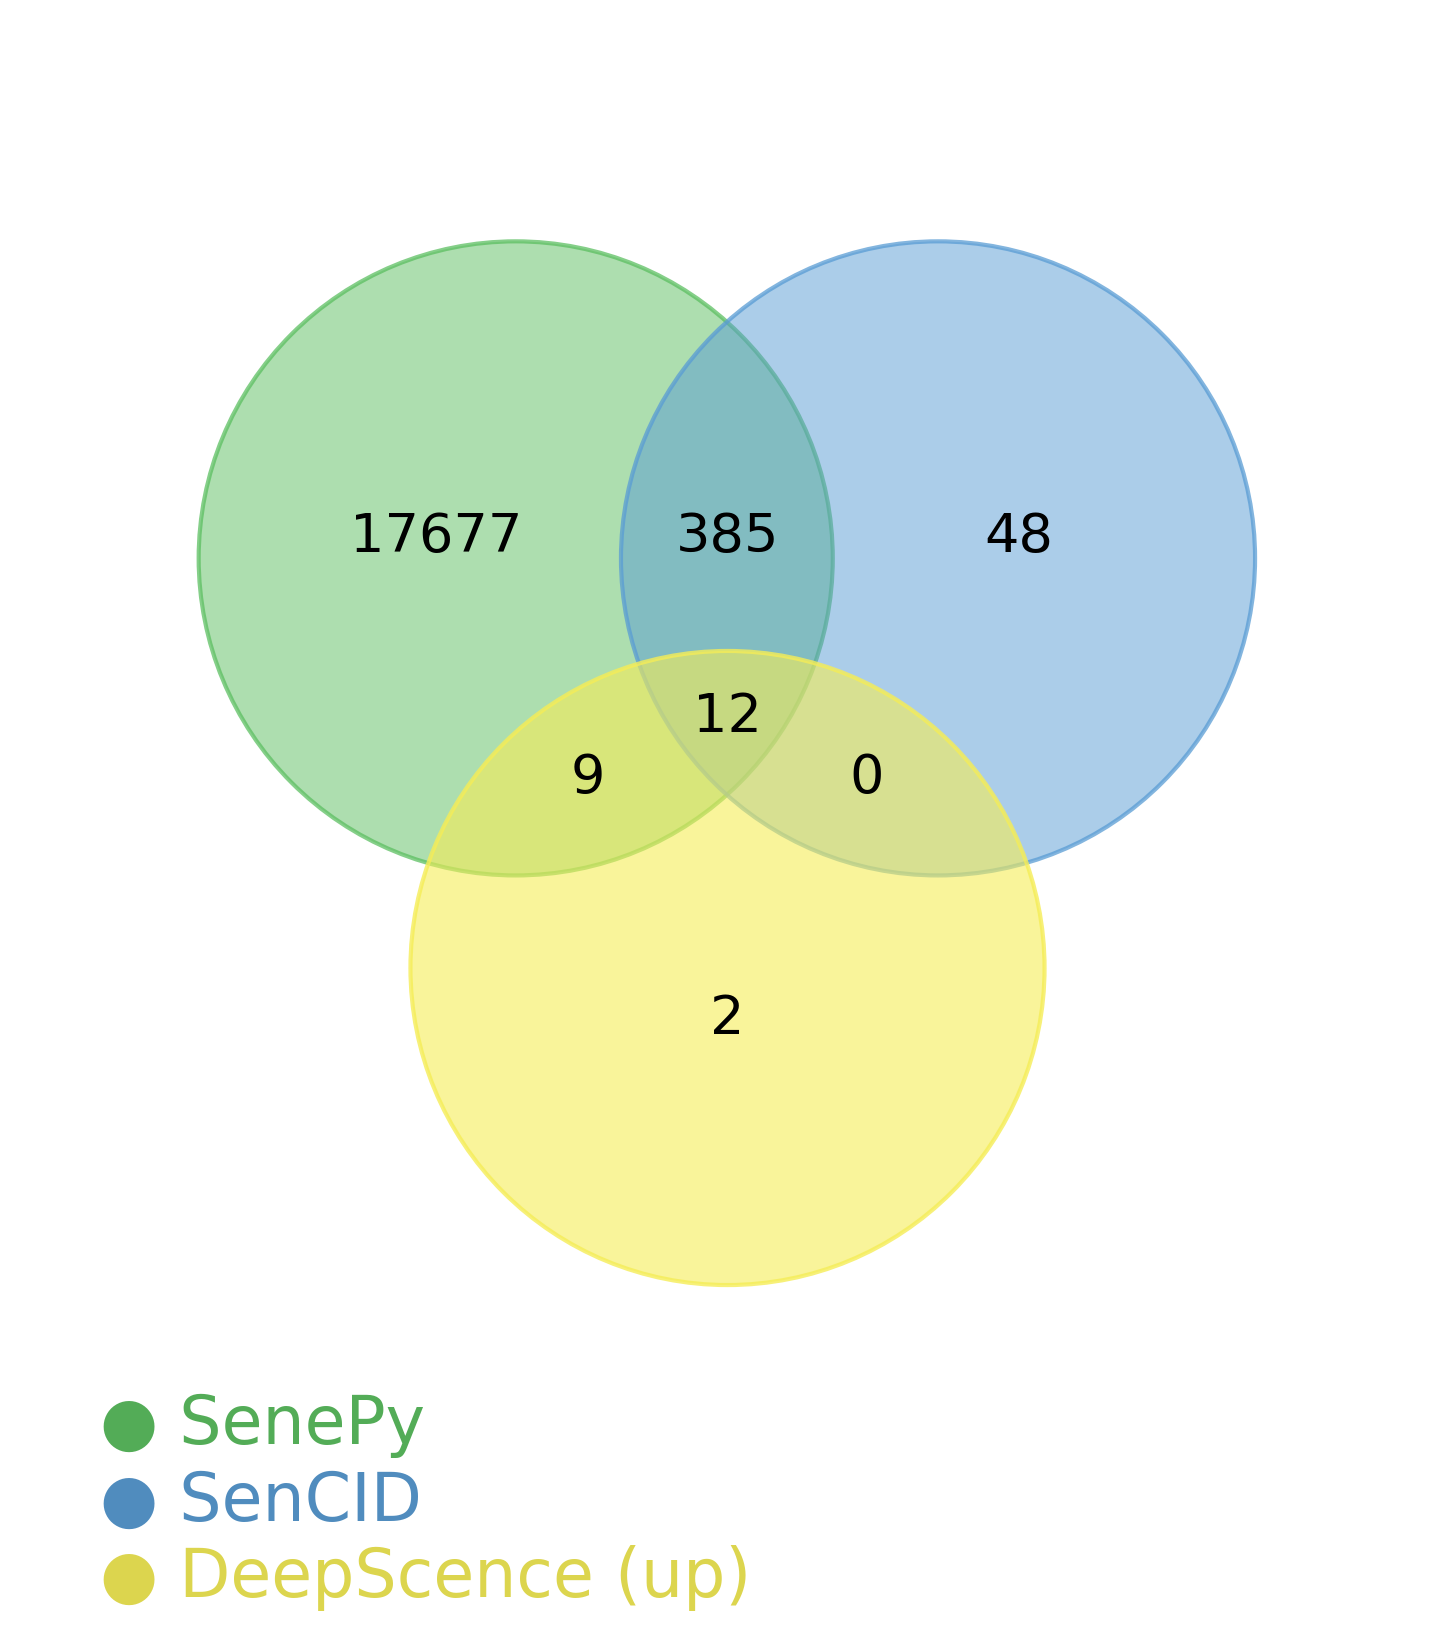

In [66]:
# 1. Формируем списки множеств и их названий для 3 ваших переменных
gene_sets = [all_sp_set, all_sid_set, all_ds_set]

names = ["SenePy", "SenCID", "DeepScence (up)"]

# 2. Создаем одну фигуру (1 строка, 1 столбец) с высоким качеством (dpi=300)
# Пропорции 6x7 дают чуть больше места снизу для аккуратного размещения легенды
fig, ax = plt.subplots(figsize=(6, 7), dpi=300)

# 3. Вызываем вашу готовую функцию plot_venn
# Она сама определит, что переданных множеств 3, вызовет venn3,
# перенесет круги, расставит крупные черные цифры и построит список под графиком
plot_venn(gene_sets=gene_sets, names=names, ax=ax, title=None)

# 4. Отображаем результат
plt.show()

In [67]:
# 2. Считаем пересечения всех трех множеств (Тройной стык)
triple_intersect = all_sp_set & all_sid_set & all_ds_set

# 3. Считаем попарные пересечения
py_cid = all_sp_set & all_sid_set
py_sc = all_sp_set & all_ds_set
sid_sc = all_sid_set & all_ds_set

# 4. Формируем структуру данных
overlap_data = [
    # --- Общее количество генов во множествах ---
    {
        "Metric": "Total SenePy (sp)",
        "Count": len(all_sp_set),
        "Genes": ", ".join(sorted("")),
    },
    {
        "Metric": "Total SenCID (sid)",
        "Count": len(all_sid_set),
        "Genes": ", ".join(sorted("")),
    },
    {
        "Metric": "Total DeepScence",
        "Count": len(all_ds_set),
        "Genes": ", ".join(sorted("")),
    },
    # --- Попарные пересечения ---
    {
        "Metric": "Intersection: SenePy & SenCID",
        "Count": len(py_cid),
        "Genes": ", ".join(sorted(py_cid)),
    },
    {
        "Metric": "Intersection: SenePy & DeepScence",
        "Count": len(py_sc),
        "Genes": ", ".join(sorted(py_sc)),
    },
    {
        "Metric": "Intersection: SenCID & DeepScence",
        "Count": len(sid_sc),
        "Genes": ", ".join(sorted(sid_sc)),
    },
    # --- Пересечение всех трех ---
    {
        "Metric": "Intersection: ALL THREE",
        "Count": len(triple_intersect),
        "Genes": ", ".join(sorted(triple_intersect)),
    },
]

# 5. Создаем итоговый DataFrame
concordance_stats_df = pd.DataFrame(overlap_data)

# Выводим на экран (без обрезки колонок, чтобы рассмотреть гены)
with pd.option_context(
    "display.max_colwidth", None, "display.expand_frame_repr", False
):
    print(concordance_stats_df)


                              Metric  Count                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

In [ ]:
concordance_stats_df.to_csv(".././7_5_sp_sid_ds_intersection_genes.csv")

In [68]:
concordance_stats_df

,Metric,Count,Genes
0,Total SenePy (sp),18083,
1,Total SenCID (sid),445,
2,Total DeepScence,23,
3,Intersection: SenePy & SenCID,397,"AASS, ABCA3, ADAM19, AHNAK2, AKAP12, AMPD3, AN..."
4,Intersection: SenePy & DeepScence,21,"CCL2, CDKN1A, CDKN2A, CDKN2B, CXCL1, CXCL8, FA..."
5,Intersection: SenCID & DeepScence,12,"CCL2, CDKN1A, CDKN2A, CDKN2B, FAS, FGF2, GDF15..."
6,Intersection: ALL THREE,12,"CCL2, CDKN1A, CDKN2A, CDKN2B, FAS, FGF2, GDF15..."
